<a href="https://colab.research.google.com/github/MarianaML07/Practica_ACO_colonia_hormigas/blob/main/QAP_ACO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Lectura del archivo de datos y definición de la Función Objetivo para QAP

In [ ]:
import numpy as np

def cargar_datos_qap(ruta_archivo):
    with open(ruta_archivo, 'r') as f:
        lineas = f.read().split()

    if not lineas:
        raise ValueError("El archivo está vacío")

    # El primer elemento es el número de nodos (n)
    n = int(lineas[0])

    # Los siguientes n * n elementos corresponden a la matriz de distancias (A)
    inicio_dist = 1
    fin_dist = inicio_dist + n * n
    A = np.array([float(x) for x in lineas[inicio_dist:fin_dist]]).reshape((n, n))

    # Los siguientes n * n elementos corresponden a la matriz de flujos (B)
    inicio_flujo = fin_dist
    fin_flujo = inicio_flujo + n * n
    B = np.array([float(x) for x in lineas[inicio_flujo:fin_flujo]]).reshape((n, n))

    return n, A, B

def funcion_objetivo_qap(p, A, B):
    """
    Calcula el costo de una asignación dada por la permutación p.
    p es una lista o array que representa a qué locación se asigna cada instalación.
    A: Matriz de distancias entre locaciones.
    B: Matriz de flujos entre instalaciones.
    """
    n = len(p)
    costo = 0.0
    for i in range(n):
        for j in range(n):
            # Flujo entre instalación i y j multiplicado por la distancia entre sus locaciones p[i] y p[j]
            #costo += A[i, j] * B[p[i], p[j]]
            costo += A[i,j]*B[pi[i],pi[j]]
    return costo

# Cargar los datos del archivo tai12.dat
ruta = '/content/tai30.dat'
n, A, B = cargar_datos_qap(ruta)

print(f"Número de nodos (n): {n}")
print("\nMatriz de Distancias (A):")
print(A)
print("\nMatriz de Flujos (B):")
print(B)

# Crear una permutación de prueba (por ejemplo, asignación identidad [0, 1, ..., n-1])
permutacion_prueba = list(range(n))
print(permutacion_prueba)
#permutacion_prueba =[7, 0, 5, 1, 10, 9, 2, 4, 8, 6, 11, 3]
#8 1 6 2 11 10 3 5 9 7 12 4

#permutacion_prueba =[7, 0, 5, 1, 10, 9, 2, 4, 8, 6, 11, 3]
#permutacion_prueba =[4, 9, 3, 12, 1, 8, 0, 10, 11, 13, 6, 14, 2, 7, 5]
permutacion_prueba =[ 18, 17, 3, 23, 29, 24, 4, 6, 0, 21, 27, 19, 10, 12, 8, 15, 7, 9, 16, 20, 11, 28, 1, 14, 2, 13, 25, 26, 22, 5]

costo_prueba = funcion_objetivo_qap(permutacion_prueba, A, B)
print(f"\nPermutación de prueba: {permutacion_prueba}")
print(f"Costo de la función objetivo: {costo_prueba}")

Número de nodos (n): 30

Matriz de Distancias (A):
[[ 0. 27. 56. 28. 64. 98. 69. 69. 93. 35. 41. 67. 12. 33.  1. 71. 72. 26.
  86. 67. 67. 24. 10. 46. 56. 56. 69. 53. 48. 74.]
 [27.  0. 43. 94. 29. 64. 97. 38. 12. 99. 51. 87. 76. 71. 47. 47.  9. 71.
  20. 81. 99. 45. 56. 15. 99. 64. 57. 84. 83. 61.]
 [56. 43.  0. 25. 41.  8. 46. 52. 22. 33. 68. 52. 28. 75. 99.  6. 85. 65.
  47. 90. 24. 79. 70. 28. 19. 87. 80.  4. 21. 34.]
 [28. 94. 25.  0. 12. 20. 67. 24. 94. 10. 64. 52. 92. 49. 68. 65. 66. 28.
  81. 17. 58. 99. 90. 70. 17. 57. 37.  2. 37.  3.]
 [64. 29. 41. 12.  0. 43. 20. 68. 35. 60. 23. 48. 40. 10. 42. 83. 82. 27.
  49. 15. 34. 50. 42. 26. 33. 23. 16. 69. 97. 13.]
 [98. 64.  8. 20. 43.  0. 35. 80. 40. 55. 30. 22. 76. 55. 56. 91. 74. 82.
  96.  2. 13.  4.  4. 35. 48. 29. 42. 56.  3. 30.]
 [69. 97. 46. 67. 20. 35.  0. 60. 81. 37. 42.  3. 17. 25. 37. 26. 88. 95.
  55. 53. 62. 22. 44. 86. 43. 43. 40. 36. 53. 34.]
 [69. 38. 52. 24. 68. 80. 60.  0. 59. 43. 50. 58. 62. 43.  9. 22. 64. 46.


Mejor ruta encontrada: [2, 1, 5, 4, 0, 3, 2]
Mejor distancia: 30


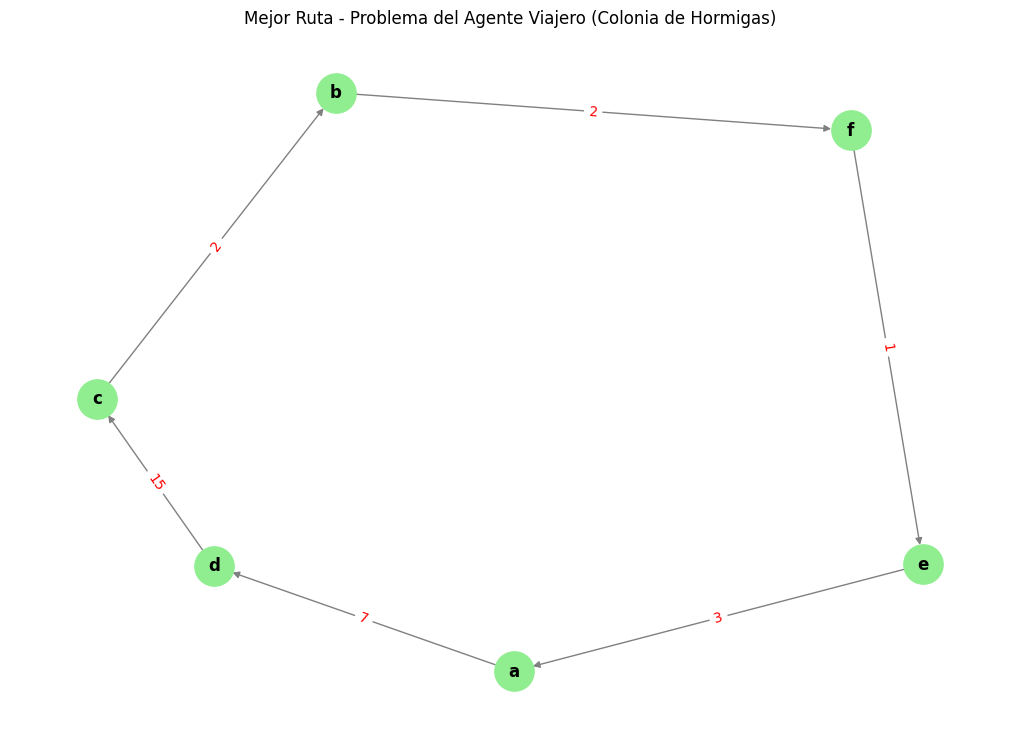

In [ ]:
import random
import matplotlib.pyplot as plt
import networkx as nx
nodos ={'a':0, 'b':1, 'c':2, 'd':3, 'e':4, 'f':5, 'g':6, 'h':7, 'i':8, 'j':9}

#matriz de feromonas
Tao = [
[ 0,  4,  3,  2,  1,  2],
[ 2,  0,  1,  2,  0,  5],
[ 4,  5,  0,  2,  2,  3],
[ 0,  0,  0,  0,  0,  4],
[ 4,  4,  0,  3,  0,  2],
[ 2,  0,  2,  0,  5,  0]
]

#matriz de distancia
Eta =[
[-1,  3,  6,  7,  9, 10],
[ 8, -1, 10,  8, -1,  2],
[ 4,  2, -1,  9,  7,  9],
[15, -1, 15, -1, 15,  4],
[ 3,  4, -1, 10, -1,  7],
[10, 15,  9, -1,  1, -1]
]


num_nodos = len(Eta)

# Parámetros del algoritmo ACO
Q = 100
rho = 0.5 # Tasa de evaporación
num_hormigas = 10
iteraciones = 50
alpha = 1.0
beta = 2.0

mejor_distancia_global = float('inf')
mejor_ruta_global = []

for it in range(iteraciones):
    rutas = []
    distancias_rutas = []

    for k in range(num_hormigas):
        # Cada hormiga empieza en un nodo aleatorio
        nodo_actual = random.randint(0, num_nodos - 1)
        ruta = [nodo_actual]
        nodos_visitados = {nodo_actual}

        while len(nodos_visitados) < num_nodos:
            probabilidades = []
            nodos_posibles = []
            denominador = 0

            # Calcular denominador para la transición
            for j in range(num_nodos):
                if j not in nodos_visitados and Eta[nodo_actual][j] != -1:
                    # Evitar valores negativos de Tao
                    tao_val = max(0, Tao[nodo_actual][j])
                    denominador += (tao_val ** alpha) * ((1.0 / Eta[nodo_actual][j]) ** beta)

            if denominador == 0:
                break # La hormiga quedó atrapada o no tiene probabilidad de avanzar

            # Calcular probabilidades de moverse a los nodos adyacentes
            for j in range(num_nodos):
                if j not in nodos_visitados and Eta[nodo_actual][j] != -1:
                    tao_val = max(0, Tao[nodo_actual][j])
                    numerador = (tao_val ** alpha) * ((1.0 / Eta[nodo_actual][j]) ** beta)
                    probabilidades.append(numerador / denominador)
                    nodos_posibles.append(j)

            if not nodos_posibles:
                break # La hormiga quedó atrapada, no hay camino válido

            # Selección por método de la ruleta
            siguiente_nodo = random.choices(nodos_posibles, weights=probabilidades)[0]
            ruta.append(siguiente_nodo)
            nodos_visitados.add(siguiente_nodo)
            nodo_actual = siguiente_nodo

        # Completar ciclo volviendo al nodo inicial si existe el camino
        if len(ruta) == num_nodos and Eta[ruta[-1]][ruta[0]] != -1:
            ruta.append(ruta[0])

            # Calcular distancia total de la ruta
            dist_total = 0
            for i in range(len(ruta) - 1):
                dist_total += Eta[ruta[i]][ruta[i+1]]

            rutas.append(ruta)
            distancias_rutas.append(dist_total)

            # Actualizar mejor ruta global
            if dist_total < mejor_distancia_global:
                mejor_distancia_global = dist_total
                mejor_ruta_global = ruta.copy()

    # Evaporación de feromonas
    for i in range(num_nodos):
        for j in range(num_nodos):
            if Tao[i][j] != -1:
                Tao[i][j] = max(0, Tao[i][j] * (1 - rho))

    # Actualización de feromonas aportadas por las hormigas
    for i in range(len(rutas)):
        r = rutas[i]
        d = distancias_rutas[i]
        if d > 0:
            delta_tao = Q / d
            for j in range(len(r) - 1):
                Tao[r[j]][r[j+1]] += delta_tao

print(f"Mejor ruta encontrada: {mejor_ruta_global}")
print(f"Mejor distancia: {mejor_distancia_global}")

# Visualización de la mejor ruta encontrada
if mejor_ruta_global:
    G = nx.DiGraph()

    # Nombres de los nodos a partir del diccionario
    nombres_nodos = list(nodos.keys())

    for i in range(len(mejor_ruta_global)-1):
        u = mejor_ruta_global[i]
        v = mejor_ruta_global[i+1]
        peso = Eta[u][v]
        G.add_edge(nombres_nodos[u] if u < len(nombres_nodos) else str(u),
                   nombres_nodos[v] if v < len(nombres_nodos) else str(v),
                   weight=peso)

    pos = nx.spring_layout(G, seed=42)
    edge_labels = nx.get_edge_attributes(G, 'weight')

    plt.figure(figsize=(10, 7))
    nx.draw(G, pos, with_labels=True, node_color='lightgreen', node_size=800, font_size=12, font_weight='bold', arrows=True, edge_color='gray')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red')

    plt.title('Mejor Ruta - Problema del Agente Viajero (Colonia de Hormigas)')
    plt.show()
else:
    print("No se encontró una ruta completa que visite todos los nodos en las iteraciones dadas.")
